# 2.1.2 BÀI LÀM MẪU: DỰ ĐOÁN KHẢ NĂNG VỠ NỢ THẺ TÍN DỤNG
Mô hình: Decision Tree Classifier và Random Forest Classifier
Thực hiện: Lê Văn Hiếu


### Nhiệm vụ 1: Nạp dữ liệu, tiền xử lý, huấn luyện DecisionTreeClassifier với max_depth=2


DecisionTree max_depth=2 Test ROC AUC: 0.7028


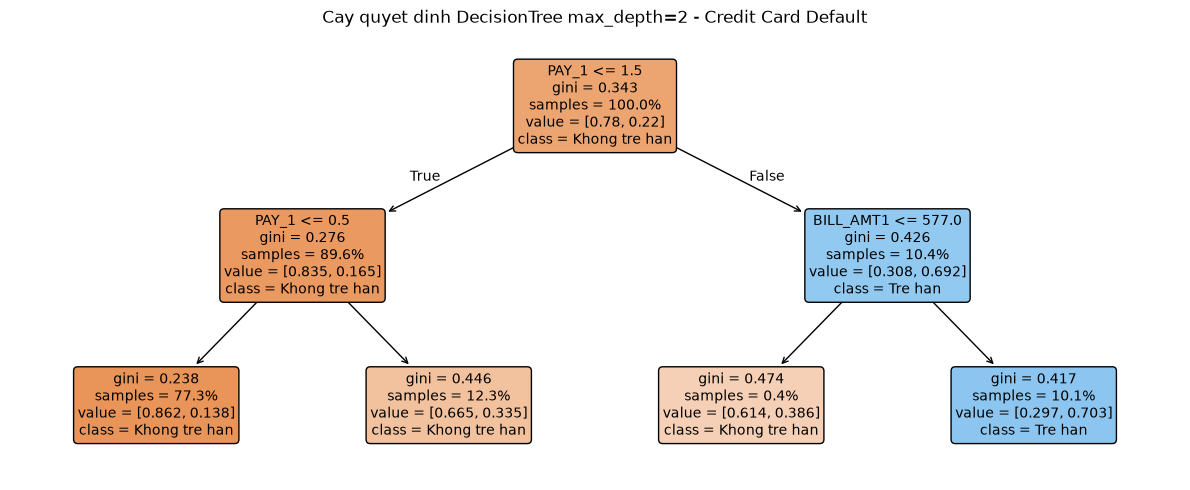

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, accuracy_score, f1_score

data_path = '../data/default_of_credit_card_clients.csv' if os.path.exists('../data/default_of_credit_card_clients.csv') else 'Lab05_ThucHanhBaiToanPhanLop/data/default_of_credit_card_clients.csv'
df_cc = pd.read_csv(data_path)
if 'PAY_0' in df_cc.columns:
    df_cc = df_cc.rename(columns={'PAY_0': 'PAY_1'})

cols_to_drop = ['ID', 'SEX', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6']
df_clean = df_cc.drop(columns=[c for c in cols_to_drop if c in df_cc.columns])

target_col = 'default payment next month'
X = df_clean.drop(columns=[target_col])
y = df_clean[target_col]
feature_names = list(X.columns)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=24
)

dt2 = DecisionTreeClassifier(max_depth=2, random_state=24)
dt2.fit(X_train, y_train)

y_prob_dt2 = dt2.predict_proba(X_test)[:, 1]
print(f"DecisionTree max_depth=2 Test ROC AUC: {roc_auc_score(y_test, y_prob_dt2):.4f}")

plt.figure(figsize=(12, 5), dpi=400)
plot_tree(
    dt2, feature_names=feature_names,
    class_names=['Khong tre han', 'Tre han'], filled=True, rounded=True, fontsize=10, proportion=True
)
plt.title("Cay quyet dinh DecisionTree max_depth=2 - Credit Card Default")
plt.tight_layout()
plt.show()


### Nhiệm vụ 2: Dùng GridSearchCV tìm max_depth tối ưu và vẽ biểu đồ errorbar Mean +- 1 SE
Ý nghĩa các thiết lập:
- scoring='roc_auc': Đánh giá diện tích dưới đường cong ROC để phản ánh khả năng phân biệt giữa lớp vỡ nợ và không vỡ nợ trên tập dữ liệu mất cân bằng.
- cv=4: Kiểm định chéo 4 phần, chia tập huấn luyện thành 4 phần bằng nhau, luân phiên 3 phần để học và 1 phần để kiểm tra.
- return_train_score=True: Lưu lại điểm số trên tập huấn luyện để so sánh với tập kiểm định, giúp quan sát hiện tượng quá khớp.


Best max_depth: 6
Best CV ROC AUC: 0.7441


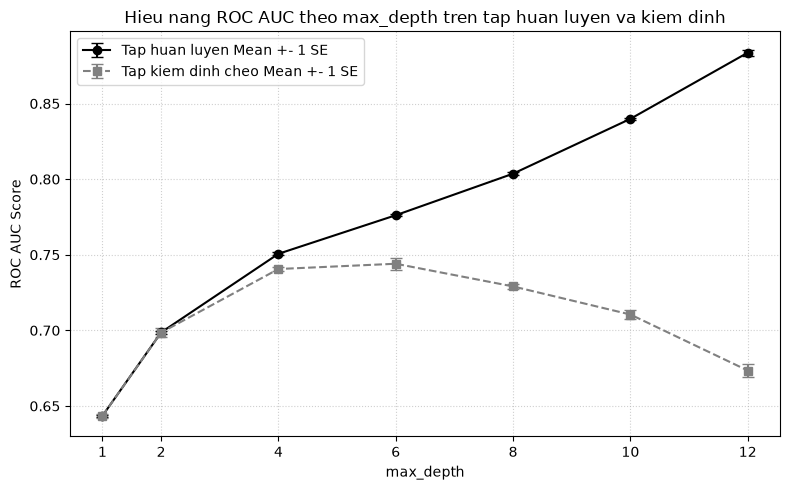

In [2]:
param_grid_dt = {'max_depth': [1, 2, 4, 6, 8, 10, 12]}
dt_search = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=24),
    param_grid=param_grid_dt,
    scoring='roc_auc',
    cv=4,
    return_train_score=True
)
dt_search.fit(X_train, y_train)

print(f"Best max_depth: {dt_search.best_params_['max_depth']}")
print(f"Best CV ROC AUC: {dt_search.best_score_:.4f}")

cv_res = pd.DataFrame(dt_search.cv_results_)
mean_tr = cv_res['mean_train_score']
se_tr = cv_res['std_train_score'] / np.sqrt(4)
mean_te = cv_res['mean_test_score']
se_te = cv_res['std_test_score'] / np.sqrt(4)

plt.figure(figsize=(8, 5))
plt.errorbar(
    param_grid_dt['max_depth'], mean_tr, yerr=se_tr,
    fmt='-o', color='black', label='Tap huan luyen Mean +- 1 SE', capsize=4
)
plt.errorbar(
    param_grid_dt['max_depth'], mean_te, yerr=se_te,
    fmt='--s', color='gray', label='Tap kiem dinh cheo Mean +- 1 SE', capsize=4
)
plt.xlabel('max_depth')
plt.ylabel('ROC AUC Score')
plt.title('Hieu nang ROC AUC theo max_depth tren tap huan luyen va kiem dinh')
plt.xticks(param_grid_dt['max_depth'])
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()


### Nhiệm vụ 3: RandomForestClassifier tuning n_estimators, subplot 1x2 và Feature Importance


Random Forest Best params: {'n_estimators': 60}
Random Forest Best CV ROC AUC: 0.7616
Test Accuracy: 0.8105
Test F1: 0.3877
Test ROC AUC: 0.7656


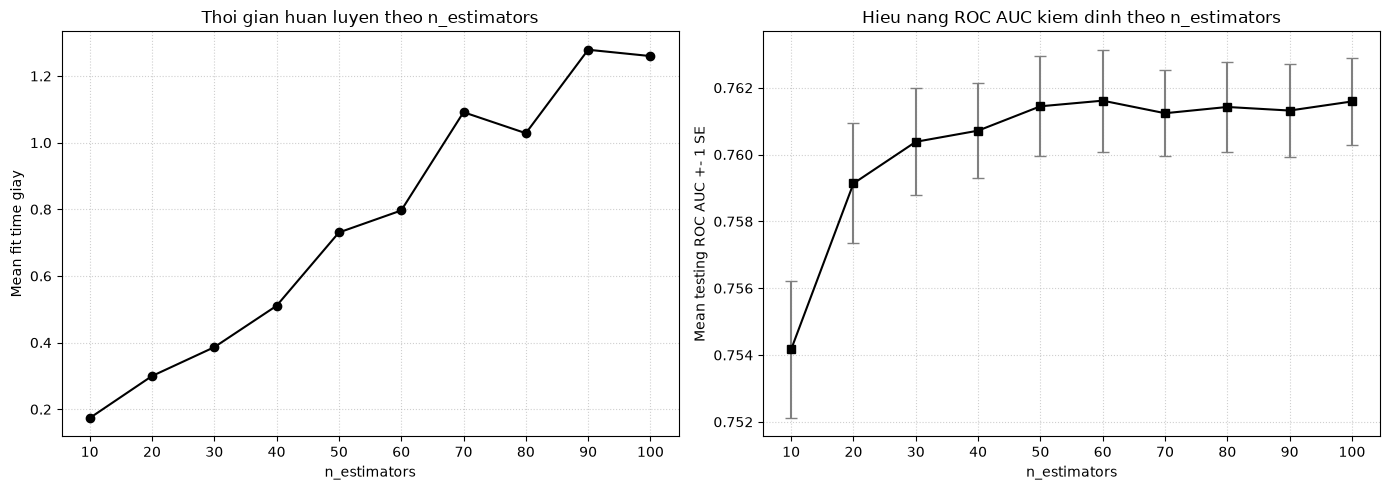

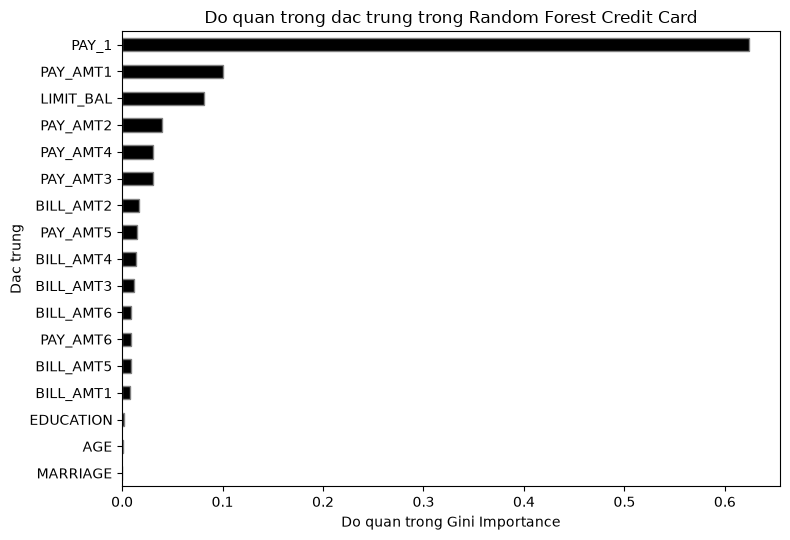

In [3]:
param_grid_rf = {'n_estimators': list(range(10, 101, 10))}
rf_search = GridSearchCV(
    estimator=RandomForestClassifier(max_depth=3, max_features='sqrt', random_state=4),
    param_grid=param_grid_rf,
    scoring='roc_auc',
    cv=4,
    return_train_score=True
)
rf_search.fit(X_train, y_train)

print(f"Random Forest Best params: {rf_search.best_params_}")
print(f"Random Forest Best CV ROC AUC: {rf_search.best_score_:.4f}")

cv_res_rf = pd.DataFrame(rf_search.cv_results_)
mean_time = cv_res_rf['mean_fit_time']
mean_te_rf = cv_res_rf['mean_test_score']
se_te_rf = cv_res_rf['std_test_score'] / np.sqrt(4)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(param_grid_rf['n_estimators'], mean_time, '-o', color='black')
axes[0].set_xlabel('n_estimators')
axes[0].set_ylabel('Mean fit time giay')
axes[0].set_title('Thoi gian huan luyen theo n_estimators')
axes[0].set_xticks(param_grid_rf['n_estimators'])
axes[0].grid(True, linestyle=':', alpha=0.6)

axes[1].errorbar(
    param_grid_rf['n_estimators'], mean_te_rf, yerr=se_te_rf,
    fmt='-s', color='black', ecolor='gray', capsize=4
)
axes[1].set_xlabel('n_estimators')
axes[1].set_ylabel('Mean testing ROC AUC +- 1 SE')
axes[1].set_title('Hieu nang ROC AUC kiem dinh theo n_estimators')
axes[1].set_xticks(param_grid_rf['n_estimators'])
axes[1].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

best_rf = rf_search.best_estimator_
fi = pd.Series(best_rf.feature_importances_, index=feature_names).sort_values(ascending=True)

plt.figure(figsize=(8, 5.5))
fi.plot(kind='barh', color='black', edgecolor='gray')
plt.xlabel('Do quan trong Gini Importance')
plt.ylabel('Dac trung')
plt.title('Do quan trong dac trung trong Random Forest Credit Card')
plt.tight_layout()
plt.show()

y_pred_rf = best_rf.predict(X_test)
print(f"Test Accuracy: {accuracy_score(y_test, y_pred_rf):.4f}")
print(f"Test F1: {f1_score(y_test, y_pred_rf):.4f}")
print(f"Test ROC AUC: {roc_auc_score(y_test, best_rf.predict_proba(X_test)[:, 1]):.4f}")
